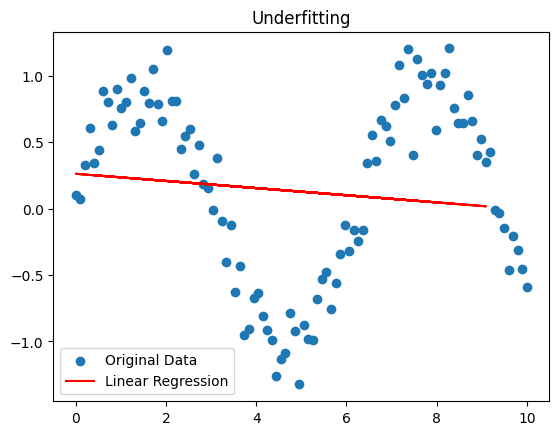

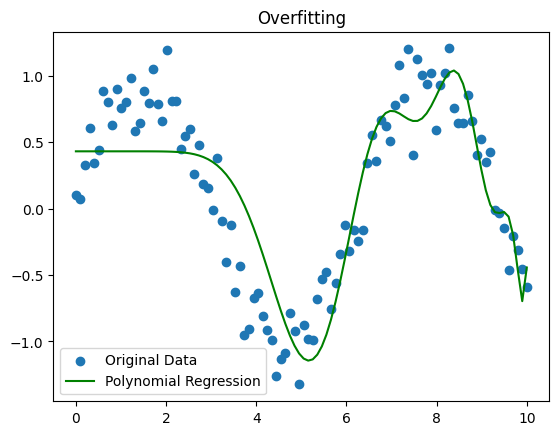

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Activity 1.1: Data Preparation
np.random.seed(42)

X = np.linspace(0, 10, 100).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.2, 100)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Activity 1.2: Underfitting using Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

plt.scatter(X, y, label="Original Data")
plt.plot(X_test, y_pred_linear, color="red", label="Linear Regression")
plt.title("Underfitting")
plt.legend()
plt.show()

# Activity 1.3: Overfitting using Polynomial Regression
poly_model = make_pipeline(
    PolynomialFeatures(degree=20),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

y_pred_poly = poly_model.predict(X_test)

# Sort X values for a proper curve
X_sorted = np.sort(X, axis=0)
y_sorted = poly_model.predict(X_sorted)

plt.scatter(X, y, label="Original Data")
plt.plot(X_sorted, y_sorted, color="green", label="Polynomial Regression")
plt.title("Overfitting")
plt.legend()
plt.show()


Linear Data Accuracy: 1.0


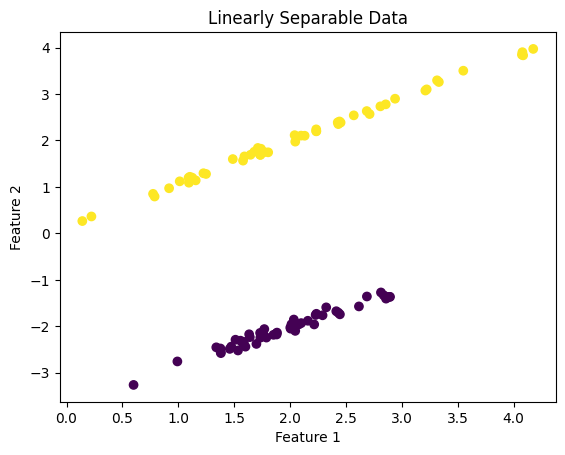

Non-linear Data Accuracy: 0.51


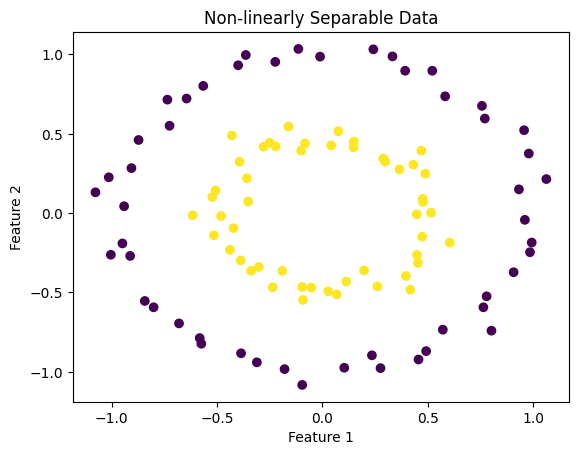

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification, make_circles

# Activity 2.1: Linearly Separable Data

X_linear, y_linear = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=2.0,
    random_state=42
)

# Train Logistic Regression
model_linear = LogisticRegression()
model_linear.fit(X_linear, y_linear)

# Predict
y_pred_linear = model_linear.predict(X_linear)

# Accuracy
print("Linear Data Accuracy:",
      model_linear.score(X_linear, y_linear))

# Plot
plt.scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear)
plt.title("Linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


# Activity 2.2: Non-linearly Separable Data

X_nonlinear, y_nonlinear = make_circles(
    n_samples=100,
    factor=0.5,
    noise=0.05,
    random_state=42
)

# Train Logistic Regression
model_nonlinear = LogisticRegression()
model_nonlinear.fit(X_nonlinear, y_nonlinear)

# Predict
y_pred_nonlinear = model_nonlinear.predict(X_nonlinear)

# Accuracy
print("Non-linear Data Accuracy:",
      model_nonlinear.score(X_nonlinear, y_nonlinear))

# Plot
plt.scatter(X_nonlinear[:, 0], X_nonlinear[:, 1],
            c=y_nonlinear)
plt.title("Non-linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [ ]:

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# Activity 1.1: Create a simulated churn dataset
X, y = make_classification(
    n_samples=1000,
    n_features=5,
    random_state=42
)

# Activity 1.2: Train-Test Split (70%-30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Activity 1.3: Train-Validation-Test Split (60%-20%-20%)

# First separate 60% training and 40% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42
)

# Now divide the remaining 40% into two equal parts
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)


Training data: (700, 5)
Testing data: (300, 5)
Training data: (600, 5)
Validation data: (200, 5)
Testing data: (200, 5)


In [ ]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression()

# Create 5 folds
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Perform cross-validation
scores = cross_val_score(
    model, X, y, cv=kfold, scoring="accuracy"
)

# Print accuracy of each fold
print("Accuracy of each fold:", scores)

# Calculate average accuracy
print("Average Accuracy:", scores.mean())


Accuracy of each fold: [0.88  0.875 0.83  0.84  0.875]
Average Accuracy: 0.86
